In [1]:
from pathlib import Path

import kagglehub
import mlflow
import pandas as pd
from dotenv import load_dotenv

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold

/Users/vladpalamarchuk/Documents/Учеба/mentor/titanic/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# load_dotenv("/Users/vladpalamarchuk/.config/llm.env")
# path = kagglehub.competition_download("titanic", output_dir="../data/raw")

# for i in Path(path).iterdir():
#     print(i)

In [3]:
test_df = pd.read_csv(
    "/Users/vladpalamarchuk/.cache/kagglehub/competitions/titanic/test.csv"
)
train_df = pd.read_csv(
    "/Users/vladpalamarchuk/.cache/kagglehub/competitions/titanic/train.csv"
)

In [4]:
test_df

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
train_df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [7]:
train_df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [8]:
# весь препроцессинг

mapping = {"male": 0, "female": 1}
train_df["Sex"] = train_df["Sex"].map(mapping)
test_df["Sex"] = test_df["Sex"].map(mapping)

array([[<Axes: title={'center': 'PassengerId'}>,
        <Axes: title={'center': 'Survived'}>,
        <Axes: title={'center': 'Pclass'}>],
       [<Axes: title={'center': 'Sex'}>, <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'SibSp'}>],
       [<Axes: title={'center': 'Parch'}>,
        <Axes: title={'center': 'Fare'}>, <Axes: >]], dtype=object)

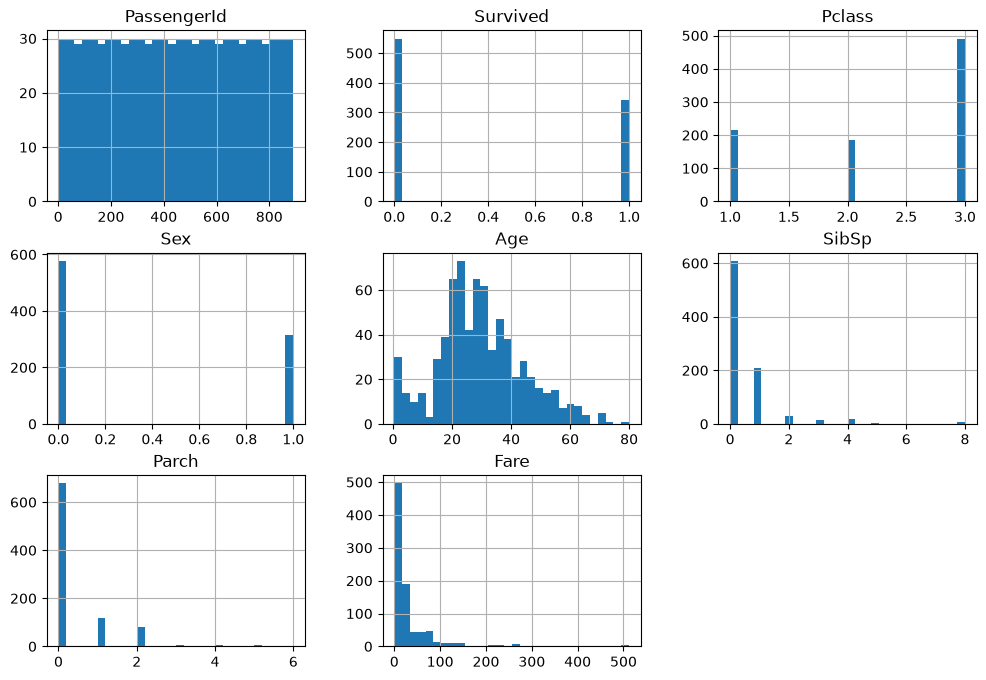

In [9]:
train_df.hist(figsize=(12, 8), bins=30)

Text(0.5, 1.0, 'Распределение цены билета')

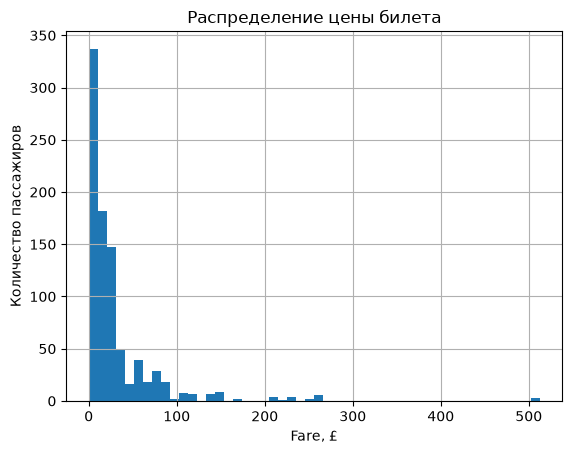

In [10]:
ax = train_df["Fare"].hist(bins=50)
ax.set_xlabel("Fare, £")
ax.set_ylabel("Количество пассажиров")
ax.set_title("Распределение цены билета")

In [11]:
train_df["Fare"].value_counts().sort_index()

Fare
0.0000      15
4.0125       1
5.0000       1
6.2375       1
6.4375       1
            ..
227.5250     4
247.5208     2
262.3750     2
263.0000     4
512.3292     3
Name: count, Length: 248, dtype: int64

In [12]:
# доля пропусков по каждой колонке
train_df.isna().mean().sort_values()

PassengerId    0.000000
Survived       0.000000
Pclass         0.000000
Name           0.000000
Sex            0.000000
SibSp          0.000000
Parch          0.000000
Ticket         0.000000
Fare           0.000000
Embarked       0.002245
Age            0.198653
Cabin          0.771044
dtype: float64

In [13]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Sex,891.0,0.352413,0.477990,0.00,0.0000,0.0000,1.0,1.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [14]:
pd.concat(
    [train_df.describe().T, test_df.describe().T],
    axis=1,
    keys=["train", "test"],
)

train                                                           \
             count        mean         std   min       25%       50%    75%   
PassengerId  891.0  446.000000  257.353842  1.00  223.5000  446.0000  668.5   
Survived     891.0    0.383838    0.486592  0.00    0.0000    0.0000    1.0   
Pclass       891.0    2.308642    0.836071  1.00    2.0000    3.0000    3.0   
Sex          891.0    0.352413    0.477990  0.00    0.0000    0.0000    1.0   
Age          714.0   29.699118   14.526497  0.42   20.1250   28.0000   38.0   
SibSp        891.0    0.523008    1.102743  0.00    0.0000    0.0000    1.0   
Parch        891.0    0.381594    0.806057  0.00    0.0000    0.0000    0.0   
Fare         891.0   32.204208   49.693429  0.00    7.9104   14.4542   31.0   

                        test                                             \
                  max  count         mean         std     min       25%   
PassengerId  891.0000  418.0  1100.500000  120.810458  892.00  996.2500   
Survived       1.0000    NaN          NaN         NaN     NaN       NaN   
Pclass         3.0000  418.0     2.265550    0.841838    1.00    1.0000   
Sex            1.0000  418.0     0.363636    0.481622    0.00    0.0000   
Age           80.0000  332.0    30.272590   14.181209    0.17   21.0000   
SibSp          8.0000  418.0     0.447368    0.896760    0.00    0.0000   
Parch          6.0000  418.0     0.392344    0.981429    0.00    0.0000   
Fare         512.3292  417.0    35.627188   55.907576    0.00    7.8958   

                                            
                   50%      75%        max  
PassengerId  1100.5000  1204.75  1309.0000  
Survived           NaN      NaN        NaN  
Pclass          3.0000     3.00     3.0000  
Sex             0.0000     1.00     1.0000  
Age            27.0000    39.00    76.0000  
SibSp           0.0000     1.00     8.0000  
Parch           0.0000     0.00     9.0000  
Fare           14.4542    31.50   512.3292

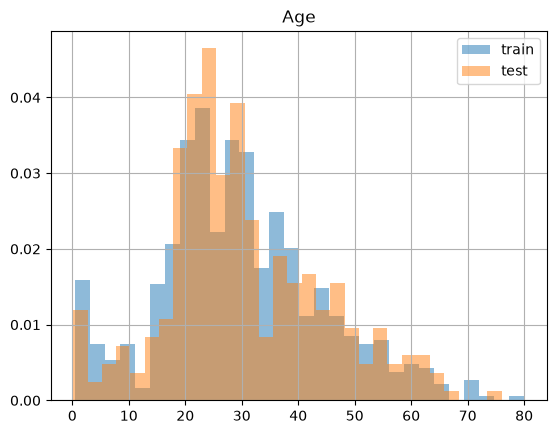

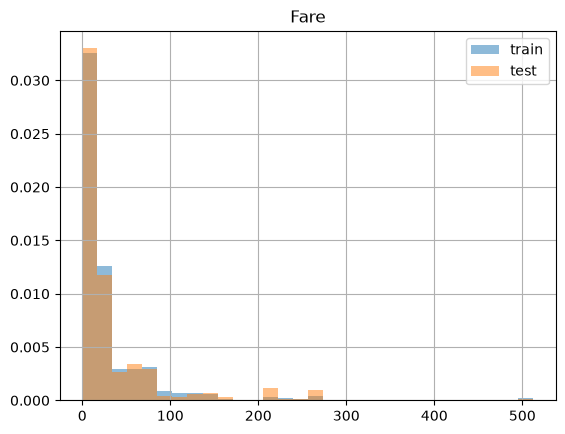

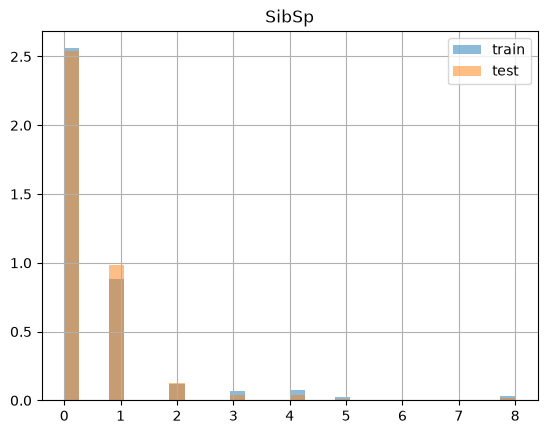

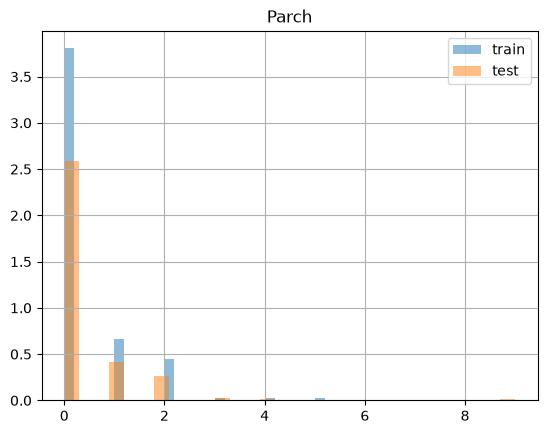

In [15]:
# распределения числовых признаков трейн/тест

import matplotlib.pyplot as plt

for col in ["Age", "Fare", "SibSp", "Parch"]:
    ax = train_df[col].hist(bins=30, alpha=0.5, density=True, label="train")
    test_df[col].hist(bins=30, alpha=0.5, density=True, label="test", ax=ax)
    ax.set_title(col)
    ax.legend()
    plt.show()

In [16]:
# распределения категориальных признаков трейн/тест

for col in ["Pclass", "Sex", "Embarked"]:
    print(
        pd.concat(
            [
                train_df[col].value_counts(normalize=True),
                test_df[col].value_counts(normalize=True),
            ],
            axis=1,
            keys=["train", "test"],
        ),
        "\n",
    )

           train      test
Pclass                    
3       0.551066  0.521531
1       0.242424  0.255981
2       0.206510  0.222488 

        train      test
Sex                    
0    0.647587  0.636364
1    0.352413  0.363636 

             train      test
Embarked                    
S         0.724409  0.645933
C         0.188976  0.244019
Q         0.086614  0.110048 



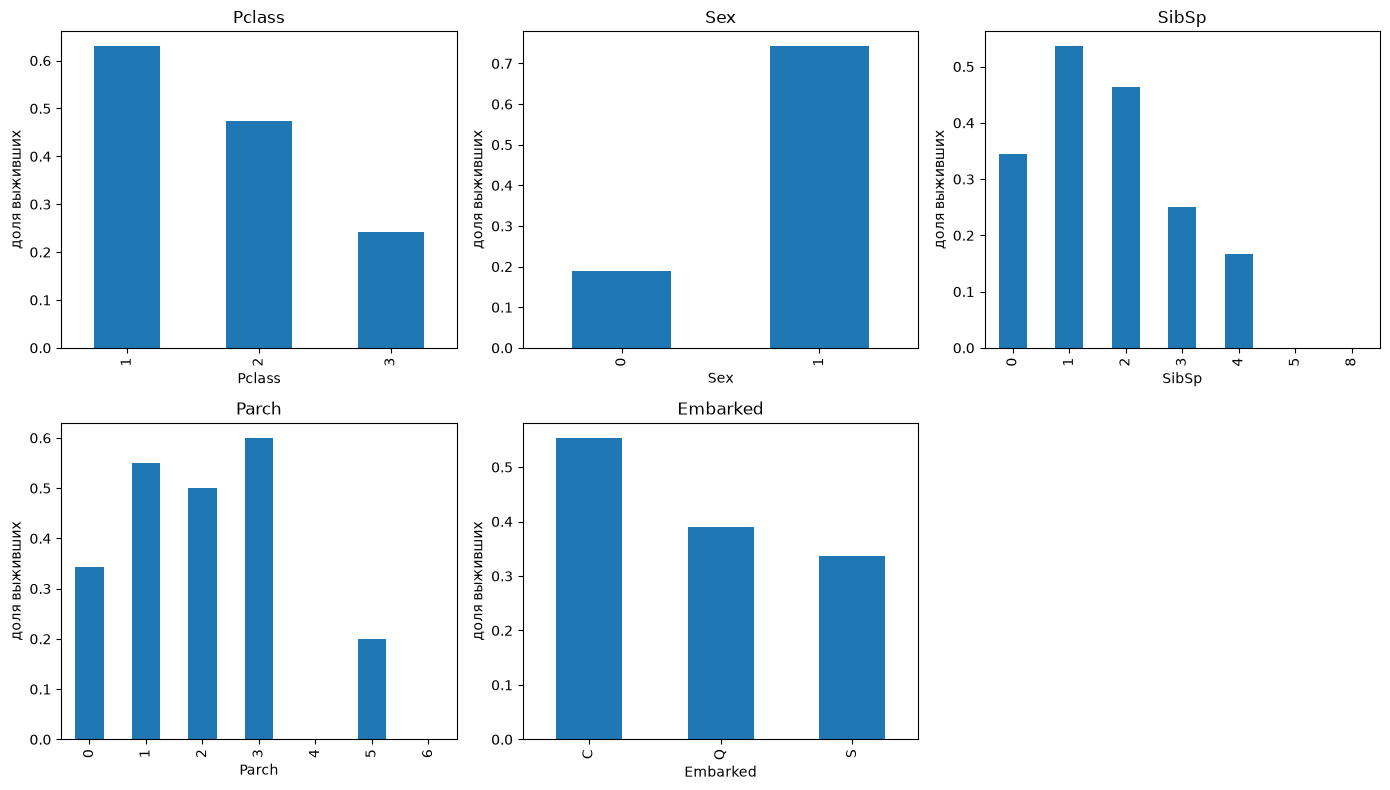

In [17]:
cat_cols = ["Pclass", "Sex", "SibSp", "Parch", "Embarked"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, cat_cols):
    train_df.groupby(col)["Survived"].mean().plot.bar(ax=ax)
    ax.set_title(col)
    ax.set_ylabel("доля выживших")
axes.flat[-1].set_visible(False)  # 6-я ячейка лишняя
plt.tight_layout()

Text(0, 0.5, 'Доля выживших')

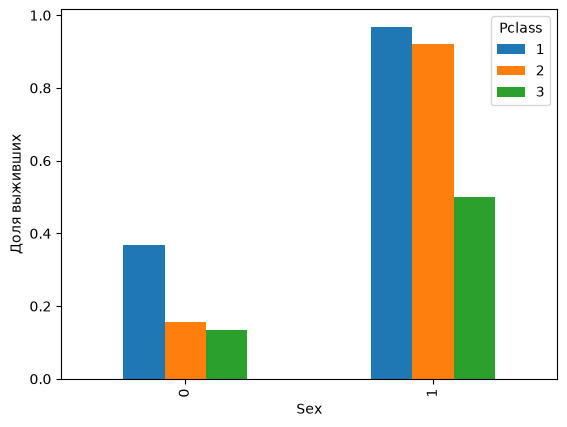

In [18]:
train_df.pivot_table(
    index="Sex", columns="Pclass", values="Survived", aggfunc="mean"
).plot.bar().set_ylabel("Доля выживших")

In [19]:
fare_bins = pd.qcut(train_df["Fare"], q=5)
fare_bins

0        (-0.001, 7.854]
1      (39.688, 512.329]
2          (7.854, 10.5]
3      (39.688, 512.329]
4          (7.854, 10.5]
             ...        
886       (10.5, 21.679]
887     (21.679, 39.688]
888     (21.679, 39.688]
889     (21.679, 39.688]
890      (-0.001, 7.854]
Name: Fare, Length: 891, dtype: category
Categories (5, interval[float64, right]): [(-0.001, 7.854] < (7.854, 10.5] < (10.5, 21.679] < (21.679, 39.688] < (39.688, 512.329]]

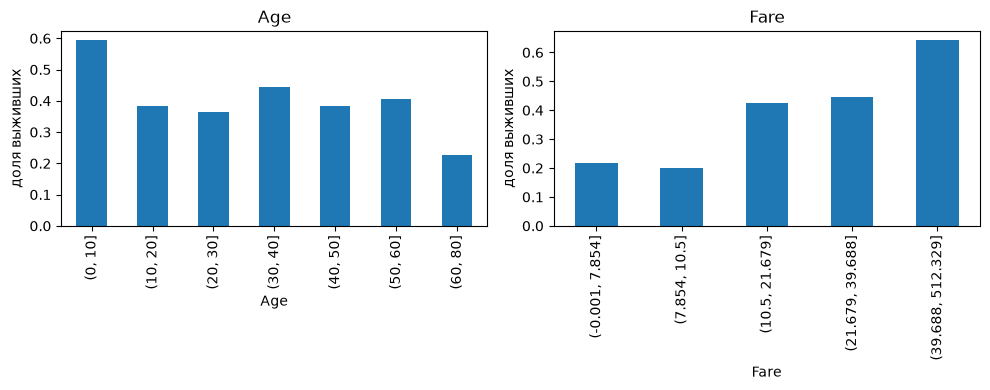

In [20]:
age_bins = pd.cut(train_df["Age"], bins=[0, 10, 20, 30, 40, 50, 60, 80])
fare_bins = pd.qcut(train_df["Fare"], q=5)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, bins, title in zip(axes, [age_bins, fare_bins], ["Age", "Fare"]):
    train_df.groupby(bins)["Survived"].mean().plot.bar(ax=ax)
    ax.set_title(title)
    ax.set_ylabel("доля выживших")
plt.tight_layout()

In [21]:
import plotly.express as px

corr = train_df.corr(numeric_only=True)
px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1)

In [22]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    int64  
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(6), str(4)
memory usage: 114.8 KB


In [ ]:
params = {
    "imputer_strategy": "mean",
    "max_iter": 100,
    "C": 1.0,
    "n_splits": 5,
    "random_state": 42,
}
DROP = ["Survived", "PassengerId", "Name", "Ticket", "Cabin", "Embarked"]  # TODO: Embarked надо onehot

In [24]:
X = train_df.drop(columns=DROP)
y = train_df["Survived"]
num_cols = X.select_dtypes(include="number").columns

In [25]:
model = make_pipeline(
    SimpleImputer(strategy=params["imputer_strategy"]),
    StandardScaler(),
    LogisticRegression(C=params["C"], max_iter=params["max_iter"]),
)
skf = StratifiedKFold(n_splits=params["n_splits"], shuffle=True, random_state=params["random_state"])

In [ ]:
MODELS = {
    "logreg": LogisticRegression,
    "rf": RandomForestClassifier,
    "hgb": HistGradientBoostingClassifier,
}

def run_cv(cfg):
    model = make_pipeline(
        SimpleImputer(strategy=cfg["imputer"]),
        StandardScaler(),
        MODELS[cfg["model"]](**cfg["model_params"]),
    )
    with wandb.init(project="titanic", config=cfg, group=cfg["model"]) as run:
        scores = cross_val_score(model, X[cfg["features"]], y, cv=skf)
        run.log({"cv_accuracy": scores.mean(), "cv_std": scores.std()})

for cfg in configs:
    run_cv(cfg)


In [7]:
import numpy as np
import pandas as pd
import wandb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from pathlib import Path


DATA = "/Users/vladpalamarchuk/.cache/kagglehub/competitions/titanic"
train_df = pd.read_csv(f"{DATA}/train.csv")
y = train_df["Survived"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

BASE = {
    "num_features": ["Pclass", "Age", "SibSp", "Parch", "Fare"],
    "cat_features": ["Sex"],
    "num_impute": "median",       # mean / median / most_frequent
    "add_missing_flag": False,    # флаг "значение было пропущено"
    "scale": True,
    "cat_encoding": "onehot",     # onehot / ordinal
    "fare_log": False,            # выбросы в Fare
}


In [ ]:
def make_features(df, cfg):
    """Преобразования без обучения: можно делать до CV."""
    df = df.copy()

    if cfg["fare_log"]:
        df["Fare"] = np.log1p(df["Fare"])

    columns = cfg["num_features"] + cfg["cat_features"]
    return df[columns]


def make_num_pipeline(cfg):
    """Числовые признаки: заполнение пропусков и (опционально) скейлинг."""
    imputer = SimpleImputer(
        strategy=cfg["num_impute"],
        add_indicator=cfg["add_missing_flag"],
    )
    steps = [("impute", imputer)]

    if cfg["scale"]:
        steps.append(("scale", StandardScaler()))

    return Pipeline(steps)


def make_cat_pipeline(cfg):
    """Категориальные признаки: заполнение пропусков и кодирование."""
    imputer = SimpleImputer(strategy="most_frequent")

    if cfg["cat_encoding"] == "onehot":
        encoder = OneHotEncoder(handle_unknown="ignore")
    else:
        encoder = OrdinalEncoder(  # 
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        )

    return Pipeline([
        ("impute", imputer),
        ("encode", encoder),
    ])


def make_model(cfg):
    """Препроцессинг + логрег. Всё, что учится на данных, внутри пайплайна."""
    preprocessor = ColumnTransformer([
        ("num", make_num_pipeline(cfg), cfg["num_features"]),
        ("cat", make_cat_pipeline(cfg), cfg["cat_features"]),
    ])
    classifier = LogisticRegression(max_iter=1000)

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", classifier),
    ])


def run(name, **changes):
    """Запускает CV с конфигом BASE + changes и логирует результат в wandb."""
    cfg = BASE | changes  # BASE + правки, changes важнее


    model = make_model(cfg)
    X = make_features(train_df, cfg)

    with wandb.init(
        project="titanic-preproc",
        name=name,
        config=cfg, 
        dir=Path.cwd().parent
    ) as wb_run:
        scores = cross_val_score(model, X, y, cv=skf, scoring="accuracy")

        wb_run.log({
            "cv_accuracy": scores.mean(),
            "cv_std": scores.std(),
        })

    print(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}")


In [9]:
# Запск эскпериментов
run("baseline")
run("fare_log", fare_log=True)
run("+embarked", cat_features=["Sex", "Embarked"])


cv_accuracy,▁
cv_std,▁
cv_accuracy,0.79012
cv_std,0.01162


baseline: 0.7901 ± 0.0116


cv_accuracy,▁
cv_std,▁
cv_accuracy,0.79124
cv_std,0.01033


fare_log: 0.7912 ± 0.0103


cv_accuracy,▁
cv_std,▁
cv_accuracy,0.79352
cv_std,0.01721


+embarked: 0.7935 ± 0.0172
